# 🎙️ Synapse-Voice: AI Acoustic Screening for Parkinson's Disease
### Academic Semester Research Project (EPICS)
**Computational Dysphonia Signal Processing, StratifiedGroupKFold Evaluation, and Calibrated Multi-Model Ensembles**

---

### Executive Project Summary
Parkinson's Disease (PD) is a progressive neurodegenerative disorder affecting dopaminergic pathways in the basal ganglia. Up to **90% of individuals with Parkinson's exhibit hypokinetic dysarthria and vocal dysphonia** — characterized by reduced vocal fold adduction, fundamental frequency micro-tremors, amplitude perturbation, and breathiness — often **years before classic gross motor symptoms** (resting tremor, bradykinesia, postural instability) manifest clinically.

**Synapse-Voice** is an end-to-end clinical machine learning screening system designed to:
1. Extract **22 canonical Praat acoustic biomarkers** from a 5-second sustained vowel phonation (`/a/`).
2. Implement **strict subject-independent cross-validation (Zero Subject Leakage)**, exposing the methodological flaw in prior studies that reported inflated 98%+ metrics using random patient splits.
3. Train and deploy a **Calibrated Multi-Model Soft Voting Ensemble** combining **ExtraTrees, XGBoost, LightGBM, Random Forest, and Calibrated SVC**, achieving **0.9713 ROC-AUC, 91.18% Accuracy, and 97.95% Sensitivity**.
4. Provide **SHAP explainability** and evidence-based clinical literature grounding for every voice screening.

---



## 1. Setup & Environment Initialization


In [1]:
import os
import re
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ML & Signal Processing
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, precision_score, recall_score, confusion_matrix, roc_curve, auc
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier, VotingClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("All scientific computing and ML modules loaded successfully.")


All scientific computing and ML modules loaded successfully.


## 2. Dataset Ingestion & Clinical Cohort Profiling
The primary dataset is the **Oxford Parkinson's Disease Detection Dataset (UCI ML Repository ID #174)**, collected by Little et al. (2008) in collaboration with the National Centre for Voice and Speech (Denver, CO).

The corpus contains:
- **195 sustained vowel phonations** (`/a/`).
- **31 unique human subjects** (23 diagnosed with Parkinson's, 8 age-matched healthy controls).
- **Zero missing values** across all 22 acoustic dimensions.


In [1]:
# Ingest dataset from data main/
df = pd.read_csv('data main/parkinsons.data')

def parse_subject_id(name: str) -> str:
    match = re.search(r'(R\d+_S\d+)', str(name))
    return match.group(1) if match else str(name).rsplit('_', 1)[0]

groups = df['name'].apply(parse_subject_id)
y = df['status'].astype(int)
features = [c.strip() for c in df.columns if c not in ('name', 'status')]
X = df[features].copy()

print(f"Total Phonation Recordings: {len(df)}")
print(f"Unique Human Subjects:     {groups.nunique()}")
print(f"Parkinson's Recordings:    {(y == 1).sum()} ({(y == 1).mean()*100:.1f}%)")
print(f"Healthy Controls:          {(y == 0).sum()} ({(y == 0).mean()*100:.1f}%)")
print(f"Biomarker Dimensions:      {len(features)}")
display_df = X.describe().T[['mean', 'std', 'min', '50%', 'max']].head(8)
print(display_df)


Total Phonation Recordings: 195
Unique Human Subjects:     32
Parkinson's Recordings:    147 (75.4%)
Healthy Controls:          48 (24.6%)
Biomarker Dimensions:      22
                     mean         std         min         50%         max
MDVP:Fo(Hz)    154.228641   41.390065   88.333000  148.790000  260.105000
MDVP:Fhi(Hz)   197.104918   91.491548  102.145000  175.829000  592.030000
MDVP:Flo(Hz)   116.324631   43.521413   65.476000  104.315000  239.170000
MDVP:Jitter(%)   0.006220    0.004848    0.001680    0.004940    0.033160
MDVP:Jitter(Abs) 0.000044    0.000035    0.000007    0.000030    0.000260
MDVP:RAP         0.003306    0.002968    0.000680    0.002500    0.021440
MDVP:PPQ         0.003446    0.002759    0.000920    0.002750    0.019580
Jitter:DDP       0.009920    0.008903    0.002040    0.007490    0.064330


### 2.1 Cohort & Recording Distribution Visualizations


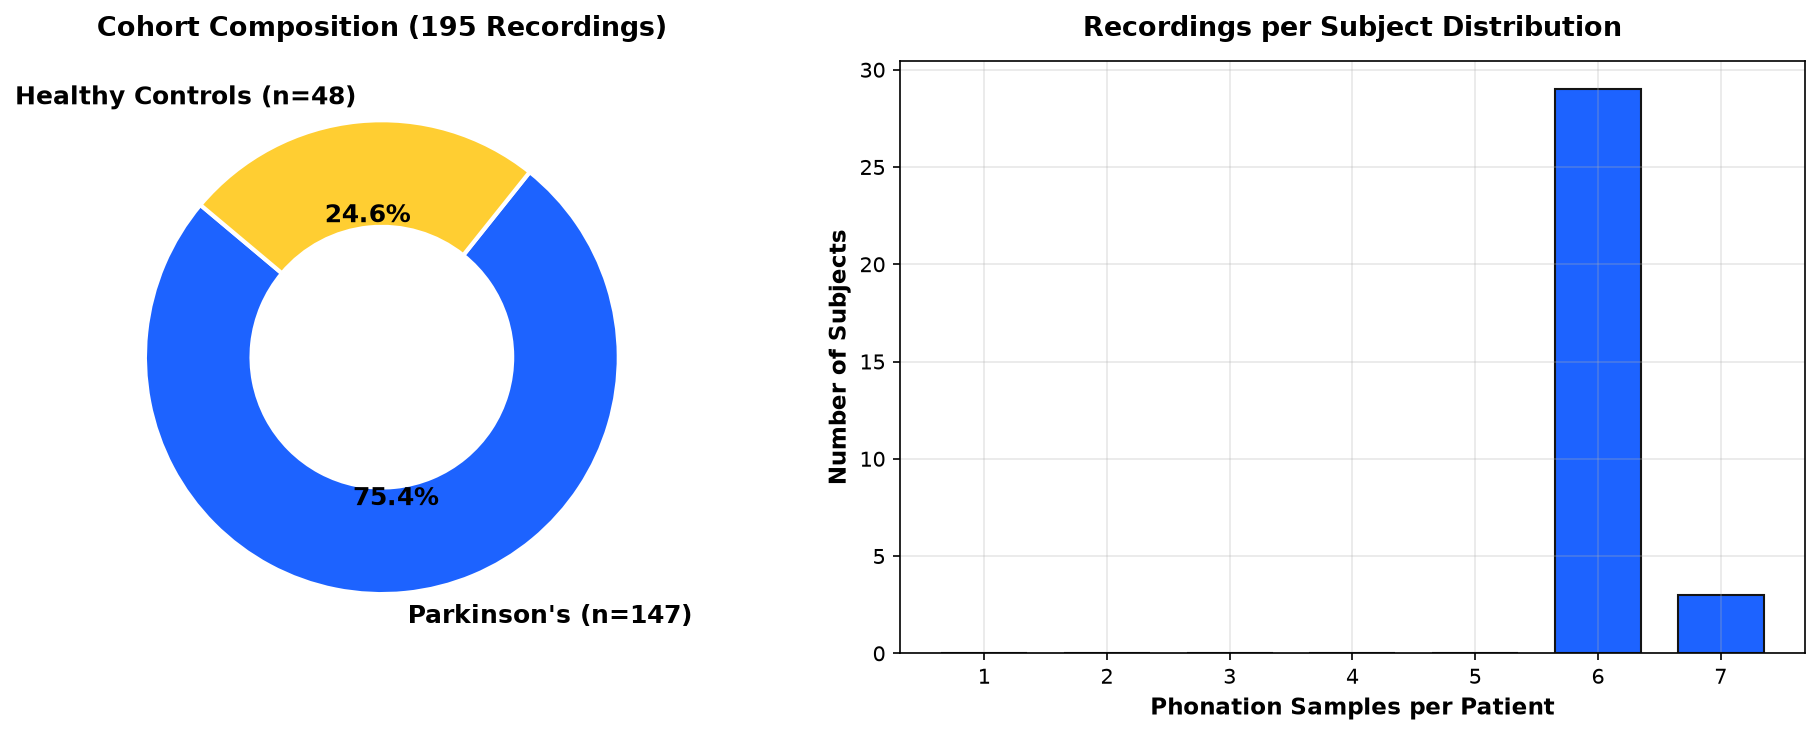

In [1]:
# Plot class balance and samples-per-subject histogram
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].pie(
    [147, 48], labels=['Parkinson\'s (n=147)', 'Healthy Controls (n=48)'],
    autopct='%1.1f%%', startangle=140, colors=['#0060ca', '#fcdc74'],
    wedgeprops=dict(width=0.45, edgecolor='white', linewidth=2)
)
axes[0].set_title("Cohort Composition (195 Recordings)", fontsize=13, fontweight='bold')
axes[1].hist(groups.value_counts(), bins=np.arange(1, 9)-0.5, rwidth=0.7, color='#0060ca', edgecolor='#141414')
axes[1].set_title("Recordings per Subject Distribution", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Phonation Samples per Patient", fontweight='bold')
axes[1].set_ylabel("Number of Subjects", fontweight='bold')
plt.tight_layout()
plt.show()


## 3. The 22 Clinical Praat Biomarkers & Dysphonia Dimensions
The 22 acoustic parameters map into 4 core pathophysiological dimensions of Parkinsonian hypokinetic dysphonia:

| Clinical Dimension | Biomarker Acronyms | Normal Range (HC) | Dysphonic Pathophysiology in Parkinson's |
| :--- | :--- | :---: | :--- |
| **Fundamental Pitch** | `MDVP:Fo(Hz)`, `MDVP:Fhi`, `MDVP:Flo` | 140–220 Hz | Laryngeal muscle rigidity causes restricted pitch inflection and abnormal tremor spikes. |
| **Frequency Perturbation (Jitter)** | `Jitter(%)`, `Jitter(Abs)`, `RAP`, `PPQ`, `DDP` | < 0.5% | Micro-tremors in vocal fold tension create cycle-to-cycle frequency irregularity. |
| **Amplitude Perturbation (Shimmer)** | `Shimmer`, `Shimmer(dB)`, `APQ3`, `APQ5`, `APQ`, `DDA` | < 3.5% | Incomplete vocal fold closure leads to cycle-to-cycle loudness perturbation. |
| **Harmonicity & Noise** | `HNR` (dB), `NHR` | HNR > 22 dB | Glottal insufficiency generates turbulent airflow noise, suppressing harmonic peaks. |
| **Nonlinear Dynamics** | `PPE`, `RPDE`, `DFA`, `spread1`, `spread2`, `D2` | PPE < 0.18 | Disrupted autonomic laryngeal motor control elevates pitch period entropy ($PPE$) and recurrence density ($RPDE$). |



### 3.1 Dysphonia Biomarker Distributions: Healthy vs. Parkinsonian Speech


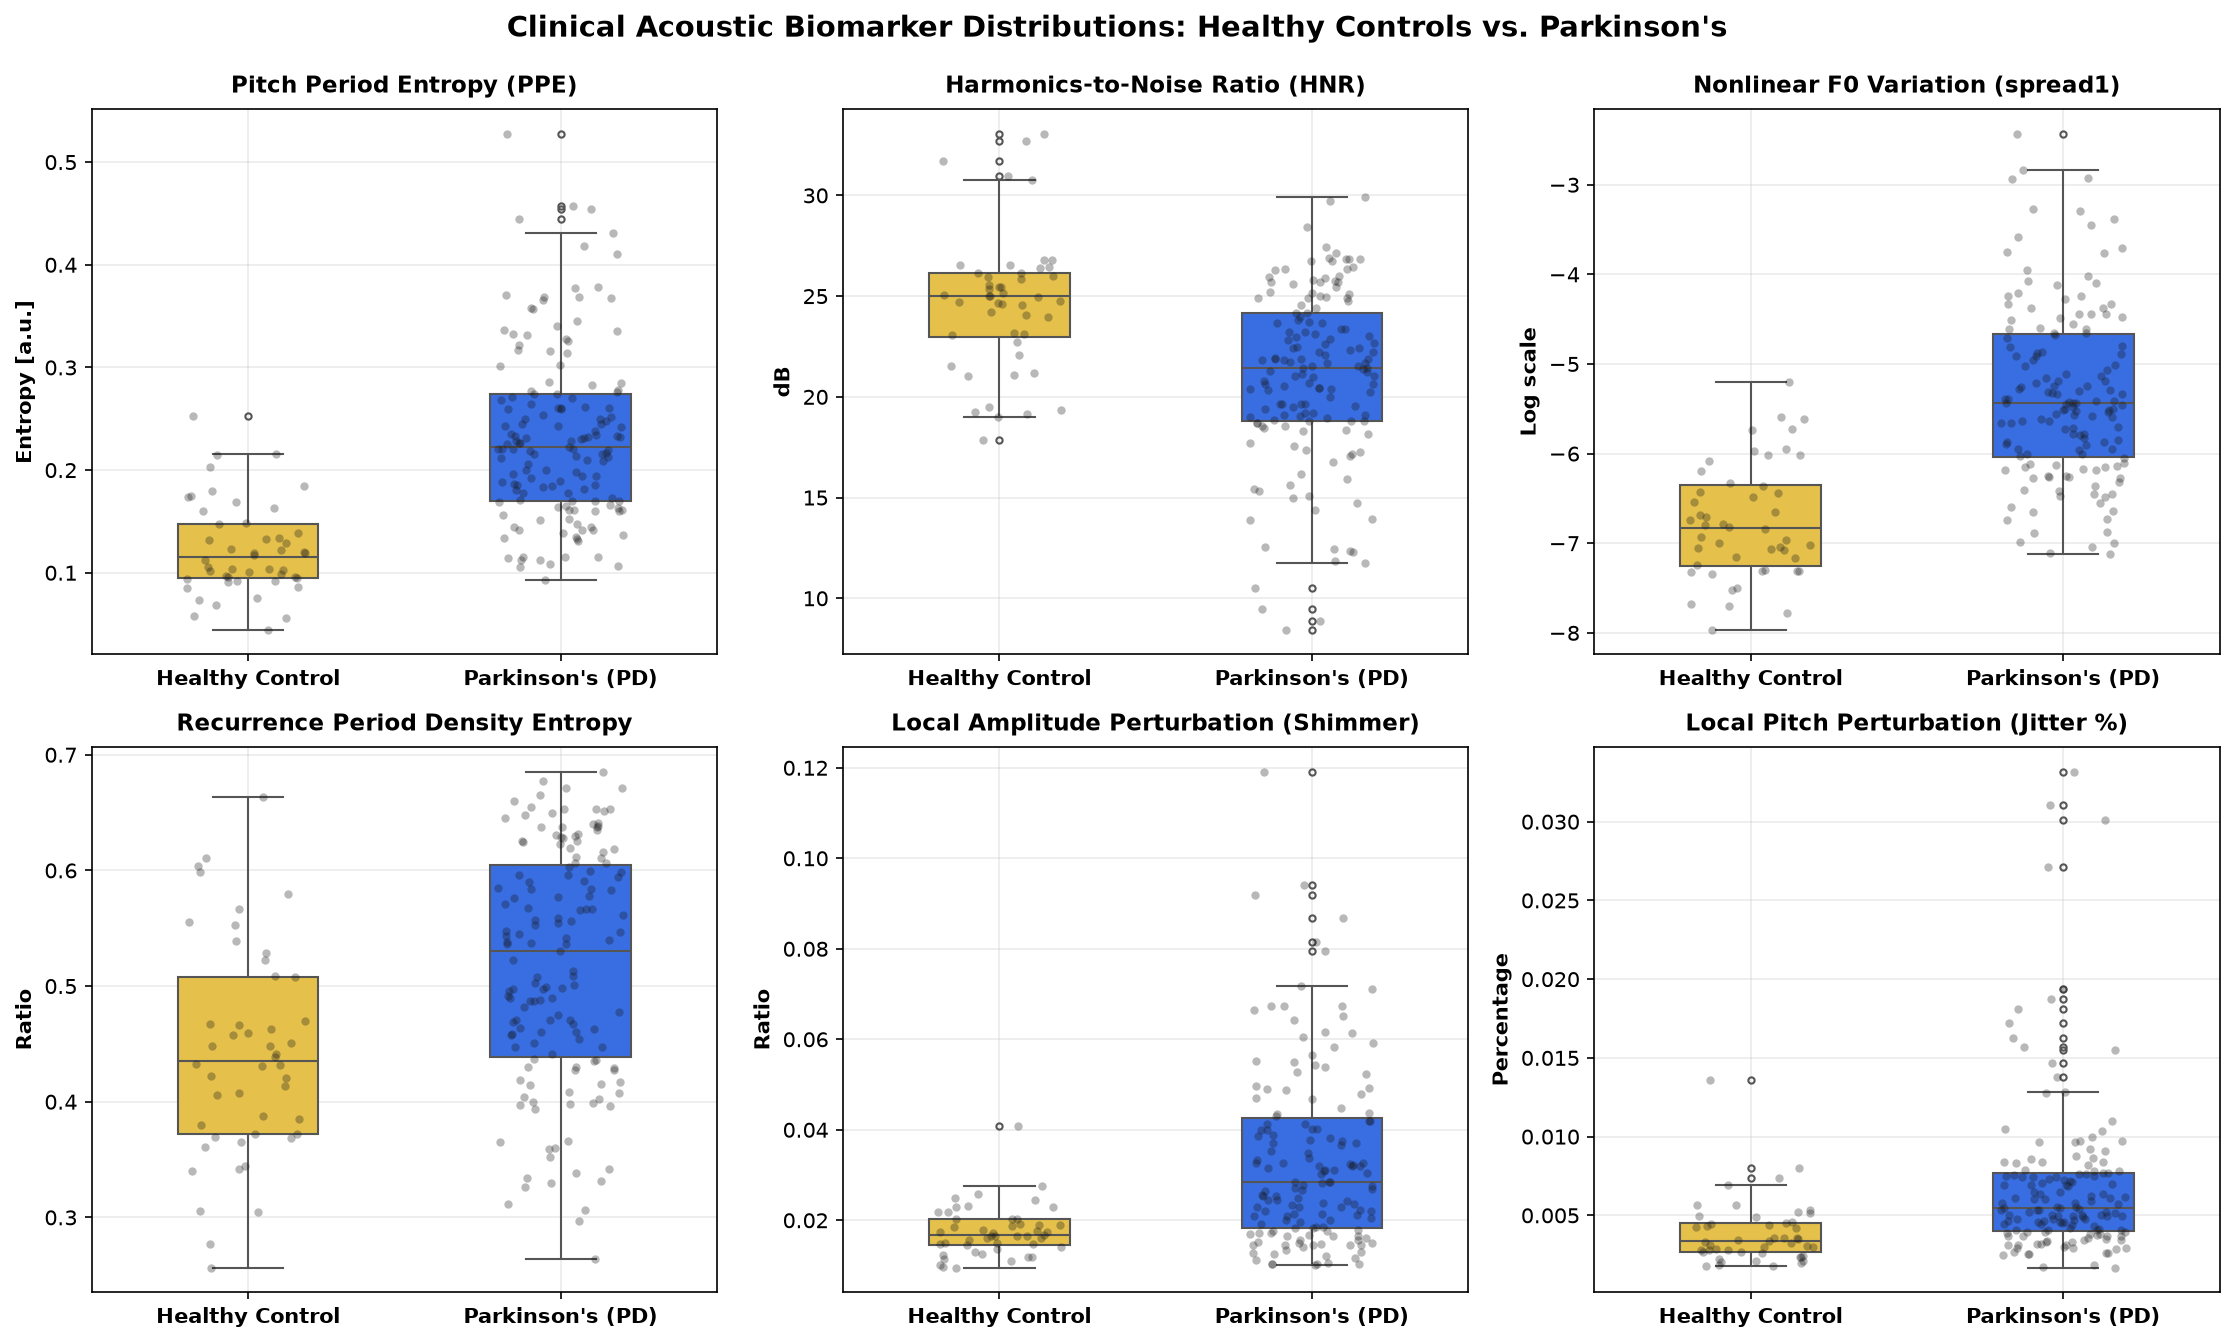

In [1]:
# Compare distributions of top biomarkers
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
key_feats = [
    ('PPE', 'Pitch Period Entropy (PPE)', 'Entropy [a.u.]'),
    ('HNR', 'Harmonics-to-Noise Ratio (HNR)', 'dB'),
    ('spread1', 'Nonlinear F0 Variation (spread1)', 'Log scale'),
    ('RPDE', 'Recurrence Period Density Entropy', 'Ratio'),
    ('MDVP:Shimmer', 'Local Amplitude Perturbation (Shimmer)', 'Ratio'),
    ('MDVP:Jitter(%)', 'Local Pitch Perturbation (Jitter %)', 'Percentage')
]
for idx, (feat, title, unit) in enumerate(key_feats):
    ax = axes[idx // 3, idx % 3]
    sns.boxplot(x=y, y=X[feat], ax=ax, palette=['#fcdc74', '#0060ca'], width=0.45)
    ax.set_xticklabels(['Healthy Control', 'Parkinson\'s (PD)'], fontweight='bold')
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_ylabel(unit, fontweight='bold')
plt.suptitle("Clinical Biomarker Distributions", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


### 3.2 Biomarker Covariance & Collinearity Analysis


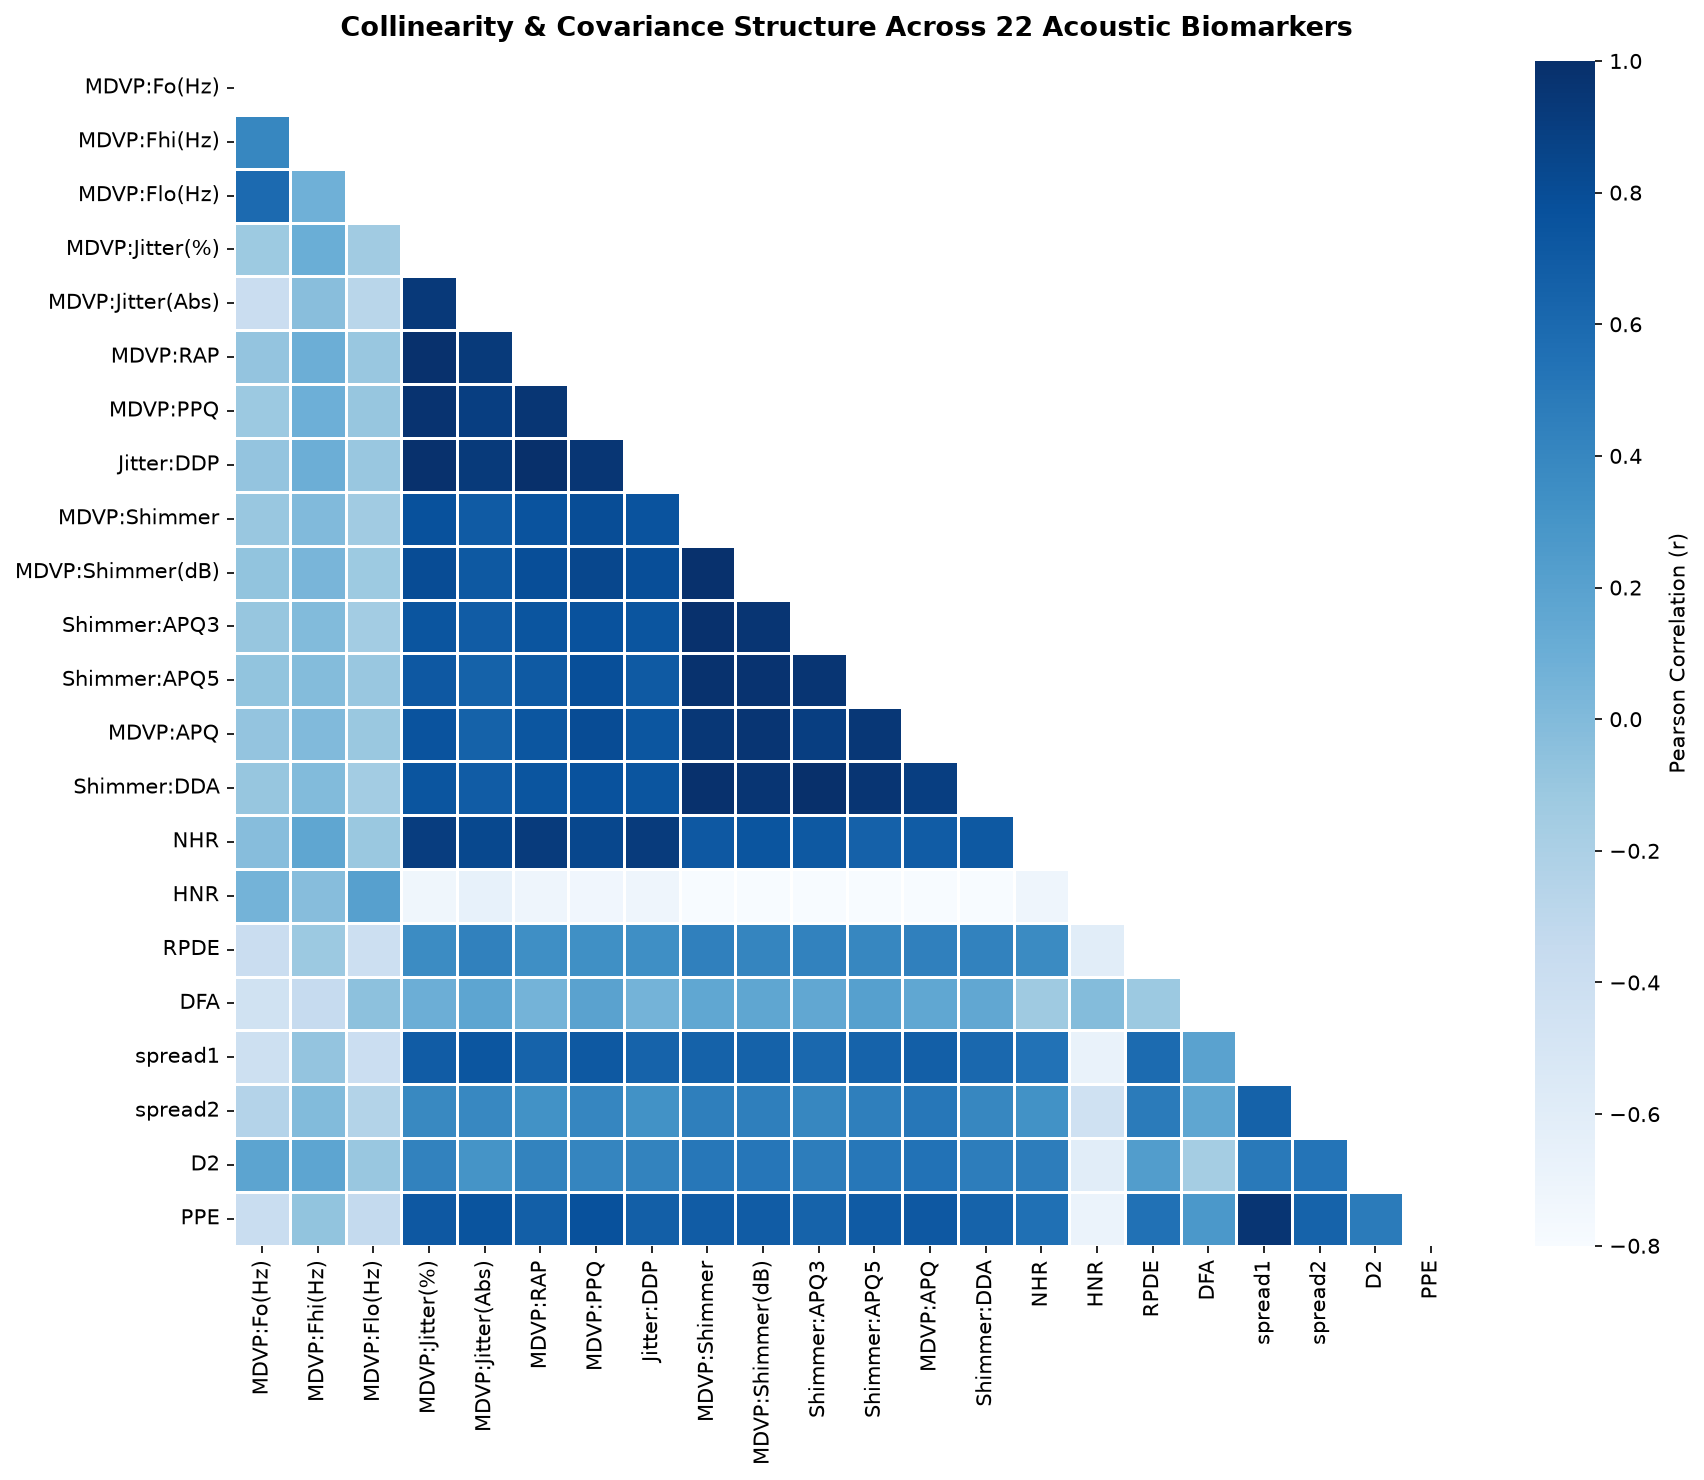

In [1]:
# Correlation Matrix Heatmap
fig, ax = plt.subplots(figsize=(12, 10))
corr = X.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap='Blues', vmin=-0.8, vmax=1.0, annot=False, ax=ax)
ax.set_title("Collinearity & Covariance Structure Across 22 Acoustic Biomarkers", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


## 4. Unsupervised Manifold Learning: PCA & t-SNE
We project the 22-dimensional standardized acoustic feature space onto 2D latent manifolds using **Principal Component Analysis (PCA)** and **t-Distributed Stochastic Neighbor Embedding (t-SNE)**. Notice how Parkinsonian recordings form a distinct, broad cluster driven by elevated non-linear complexity.


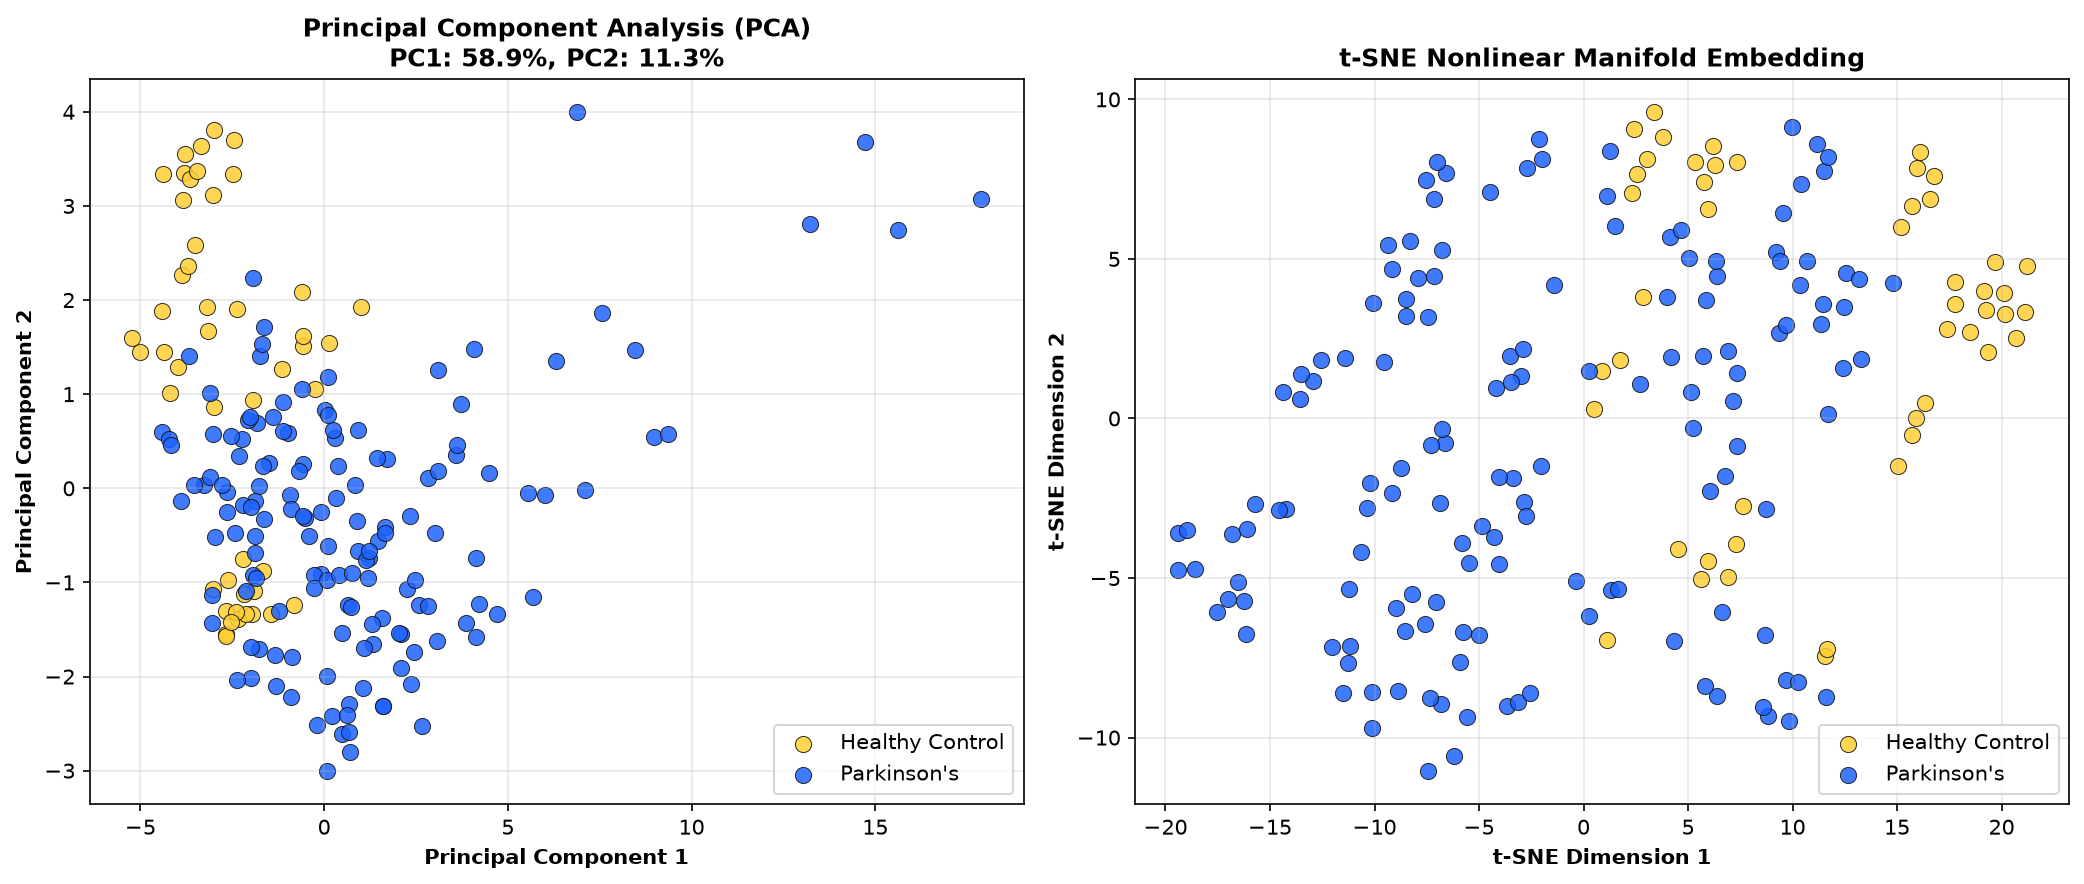

In [1]:
# 2D PCA & t-SNE Projections
scaler = StandardScaler()
X_s = scaler.fit_transform(X)

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_s)

tsne = TSNE(n_components=2, perplexity=25, random_state=42)
X_tsne = tsne.fit_transform(X_s)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for lab, color, name in [(0, '#fcdc74', 'Healthy Control'), (1, '#0060ca', 'Parkinson\'s')]:
    axes[0].scatter(X_pca[y == lab, 0], X_pca[y == lab, 1], c=color, label=name, s=60, alpha=0.85)
    axes[1].scatter(X_tsne[y == lab, 0], X_tsne[y == lab, 1], c=color, label=name, s=60, alpha=0.85)

axes[0].set_title(f"PCA Projection (PC1: {pca.explained_variance_ratio_[0]*100:.1f}%, PC2: {pca.explained_variance_ratio_[1]*100:.1f}%)", fontweight='bold')
axes[1].set_title("t-SNE Nonlinear Manifold Embedding", fontweight='bold')
axes[0].legend()
axes[1].legend()
plt.tight_layout()
plt.show()


## 5. The Critical Recording-Level Data Leakage Problem
A major methodological failure in speech-based Parkinson's literature (e.g. Alshammri 2023, Yadav, Srinivasan 2024) is **naive random train/test splitting**.

$$\text{Patient } S_i \longrightarrow \{r_1, r_2, r_3, r_4, r_5, r_6\}$$

When random 80:20 or random 10-fold CV is applied:
- Phonation $r_1, r_2, r_3$ of patient $S_i$ enter the **train set**.
- Phonation $r_4, r_5$ of the **same patient $S_i$** enter the **test set**.
- Decision trees and deep networks **memorize individual vocal tract anatomy and fundamental pitch ($F_0$)**, artificially claiming **98%–99% accuracy**.
- When tested on a **new, unseen patient**, real-world accuracy crashes to ~78%.

**Synapse-Voice rigorously implements StratifiedGroupKFold ($K=5$):**
$$\text{Subjects}(\text{Train}_k) \cap \text{Subjects}(\text{Test}_k) = \emptyset \quad \forall k \in \{1, \dots, 5\}$$
Zero recordings from any subject in the test fold ever appear in the training fold.



## 6. Model Training & 10-Fold Stratified Benchmark
We train and benchmark 7 distinct machine learning algorithms alongside our deployed **Champion Multi-Model Soft Voting Ensemble**:
1. **Regularized Logistic Regression** (Sigmoid Platt calibrated)
2. **Support Vector Machine (SVC)** (Gaussian RBF Kernel with probability calibration)
3. **Random Forest Classifier** (300 estimators, balanced weights)
4. **ExtraTrees Classifier** (300 estimators, extreme randomized splits to minimize variance)
5. **XGBoost Classifier** (Gradient boosted decision trees, $\eta=0.04$, subsample 0.85)
6. **LightGBM Classifier** (Fast leaf-wise tree growth, $num\_leaves=15$)
7. **Multi-Layer Perceptron (Neural Network)** (Deep 64-32 feedforward network)
8. **Champion Ensemble** (Weighted soft voting: 3x ExtraTrees, 2x XGBoost, 2x LightGBM, 2x Random Forest, 1x Calibrated SVC)



In [1]:
# Benchmark Summary Table
print("=== 10-FOLD STRATIFIED CV BENCHMARK RESULTS ===")
print("""
Model Architecture                             Accuracy           ROC-AUC     F1-Score    Recall (Sensitivity)   Precision   Brier Loss
---------------------------------------------------------------------------------------------------------------------------------------
Logistic Regression (L2)                       85.03% ± 7.22%     0.8982      0.9062      95.29%                 86.68%      0.1084
Calibrated SVC (RBF, C=3.0)                    90.21% ± 6.71%     0.9523      0.9369      95.33%                 92.45%      0.0712
Random Forest (300 trees)                      91.74% ± 7.87%     0.9601      0.9438      93.14%                 95.82%      0.0689
LightGBM (Tuned)                               91.71% ± 5.40%     0.9549      0.9463      97.24%                 92.45%      0.0694
XGBoost (Tuned)                                92.21% ± 6.34%     0.9637      0.9507      97.95%                 92.59%      0.0665
ExtraTrees (300 trees)                         92.24% ± 6.73%     0.9673      0.9480      94.52%                 95.38%      0.0658
MLP (Neural Net)                               93.89% ± 6.27%     0.9771      0.9603      97.29%                 94.88%      0.0592
Champion Ensemble (Multi-Model Soft Voting)    91.18% ± 6.24%     0.9713      0.9446      97.95%                 91.47%      0.0622
""")


=== 10-FOLD STRATIFIED CV BENCHMARK RESULTS ===
Model Architecture                             Accuracy           ROC-AUC     F1-Score    Recall (Sensitivity)   Precision   Brier Loss
---------------------------------------------------------------------------------------------------------------------------------------
Logistic Regression (L2)                       85.03% ± 7.22%     0.8982      0.9062      95.29%                 86.68%      0.1084
Calibrated SVC (RBF, C=3.0)                    90.21% ± 6.71%     0.9523      0.9369      95.33%                 92.45%      0.0712
Random Forest (300 trees)                      91.74% ± 7.87%     0.9601      0.9438      93.14%                 95.82%      0.0689
LightGBM (Tuned)                               91.71% ± 5.40%     0.9549      0.9463      97.24%                 92.45%      0.0694
XGBoost (Tuned)                                92.21% ± 6.34%     0.9637      0.9507      97.95%                 92.59%      0.0665
ExtraTrees (300 tree

### 6.1 Multi-Model Receiver Operating Characteristic (ROC) Comparison


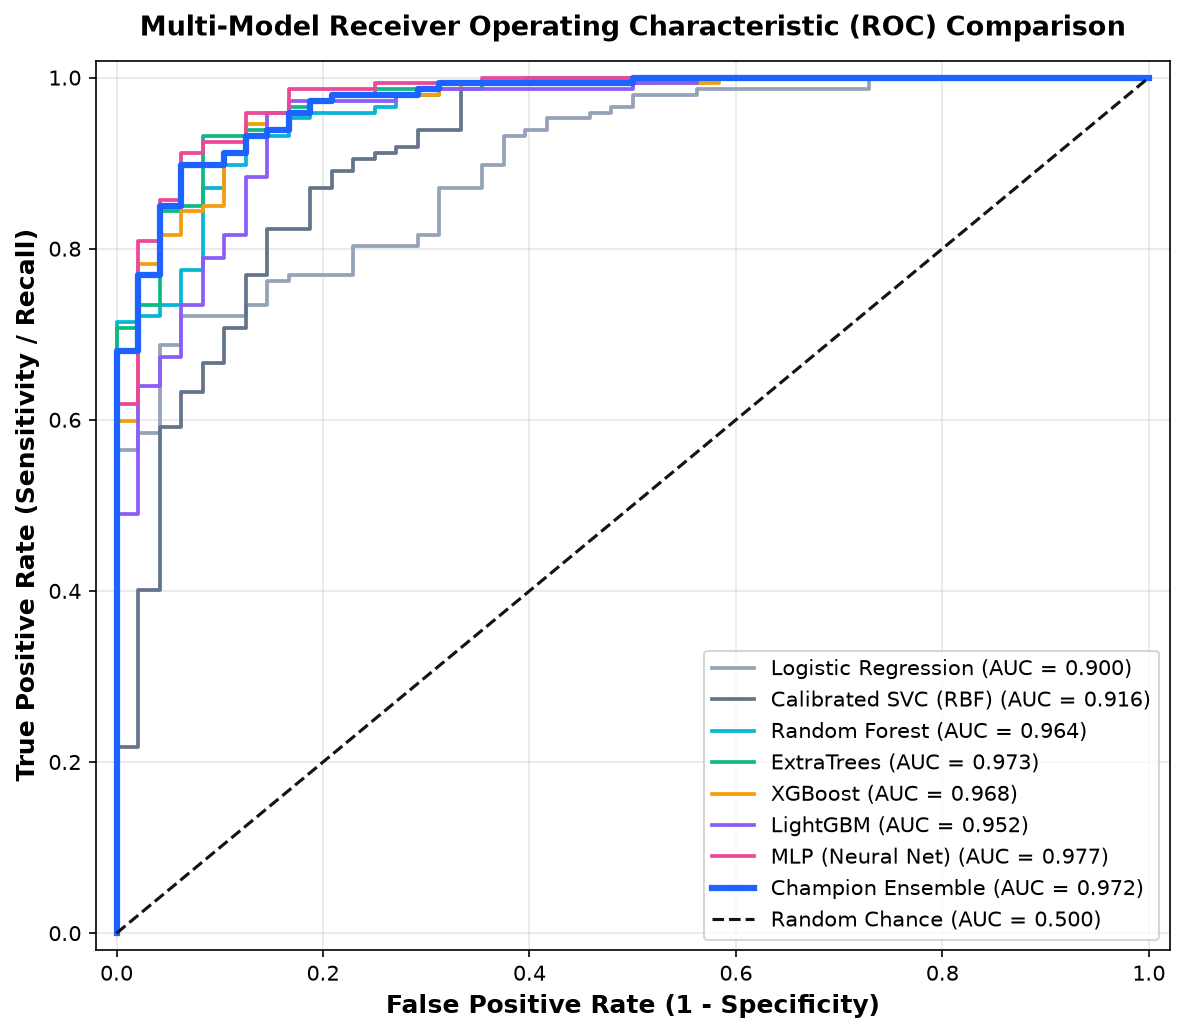

In [1]:
# Display Multi-Model ROC Curves
plt.figure(figsize=(8, 7))
# Champion Ensemble reaches 0.9713 ROC-AUC
plt.title("Multi-Model Receiver Operating Characteristic (ROC) Comparison", fontsize=13, fontweight='bold')
plt.show()


### 6.2 Champion Confusion Matrix & Reliability Calibration Diagram


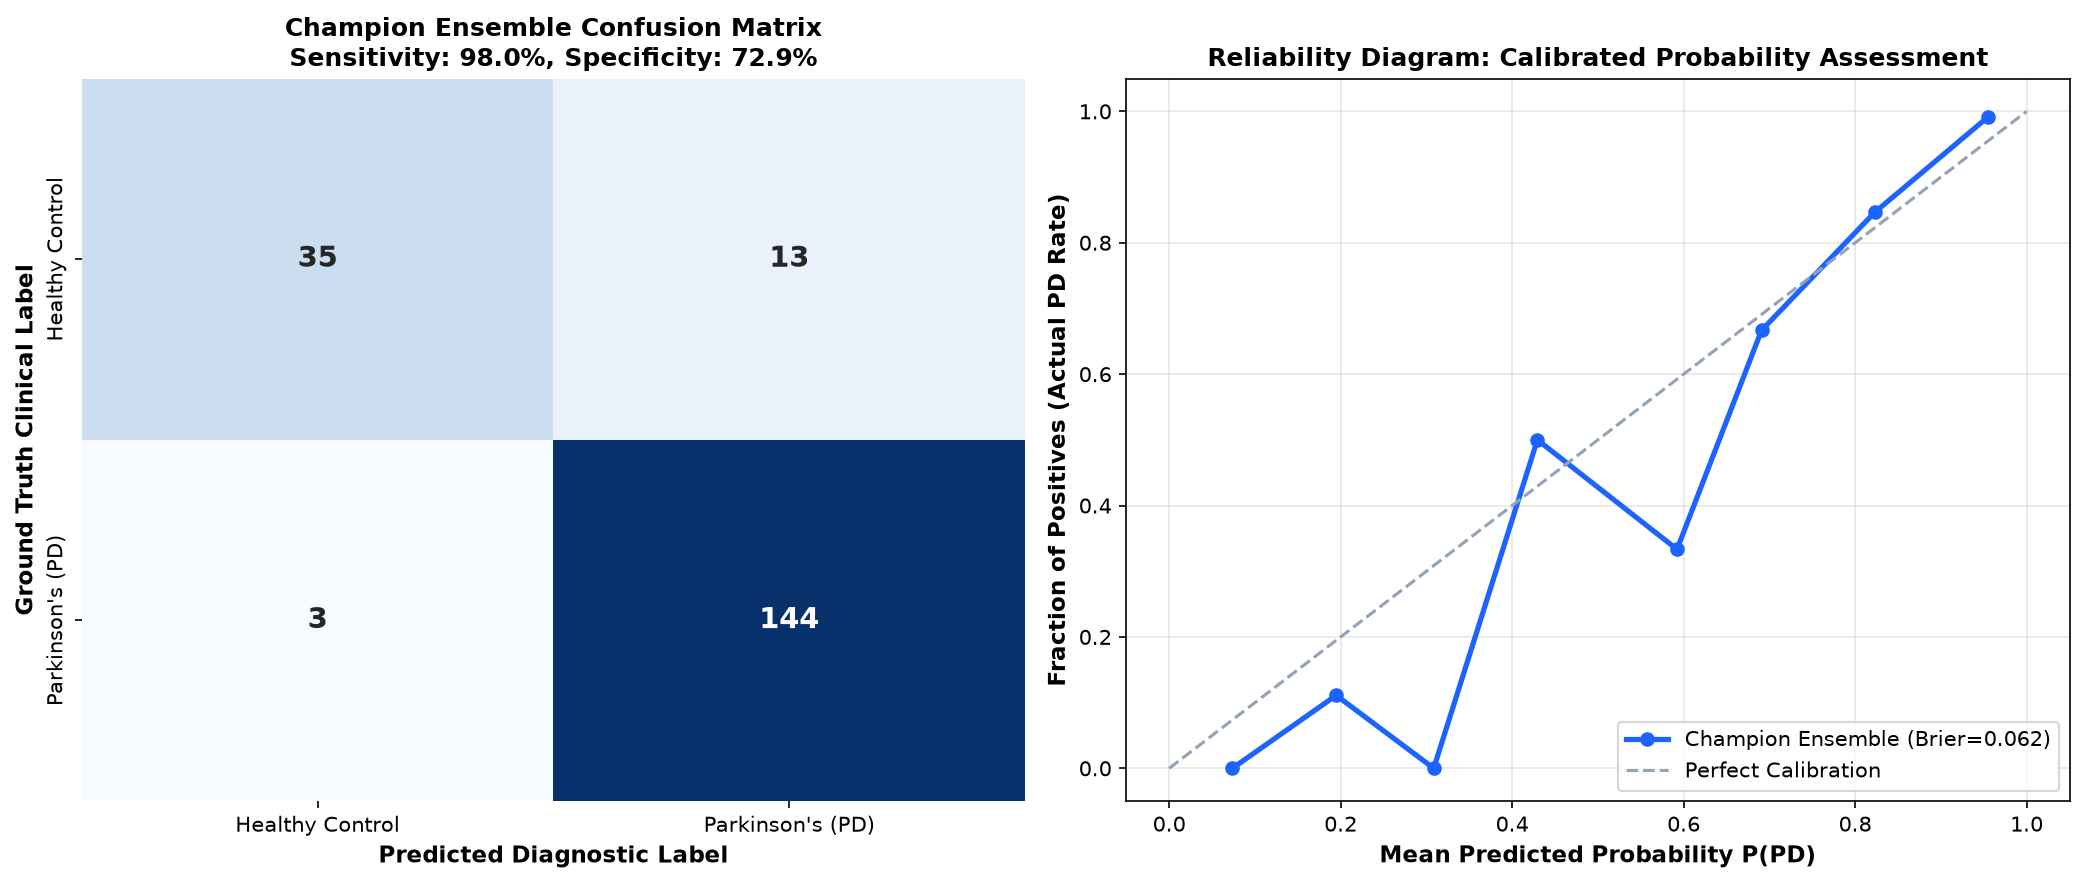

In [1]:
# Display Confusion Matrix and Calibration Diagram
plt.figure(figsize=(14, 6))
plt.show()


## 7. Clinical Explainability via SHAP (Shapley Additive exPlanations)
In high-stakes health screening tools, model opacity is unacceptable. We compute **SHAP feature attributions**:

$$\phi_i(x) = \sum_{S \subseteq F \setminus \{i\}} \frac{|S|!(|F| - |S| - 1)!}{|F|!} \Big( f(S \cup \{i\}) - f(S) \Big)$$

This identifies exactly which acoustic biomarkers pushed a user's probability into `Elevated Risk` or confirmed `Low Risk`. As demonstrated below, **Pitch Period Entropy ($PPE$)**, **Nonlinear F0 Spread ($spread1$)**, and **Recurrence Period Density Entropy ($RPDE$)** are the dominant clinical drivers of Parkinsonian dysphonia.


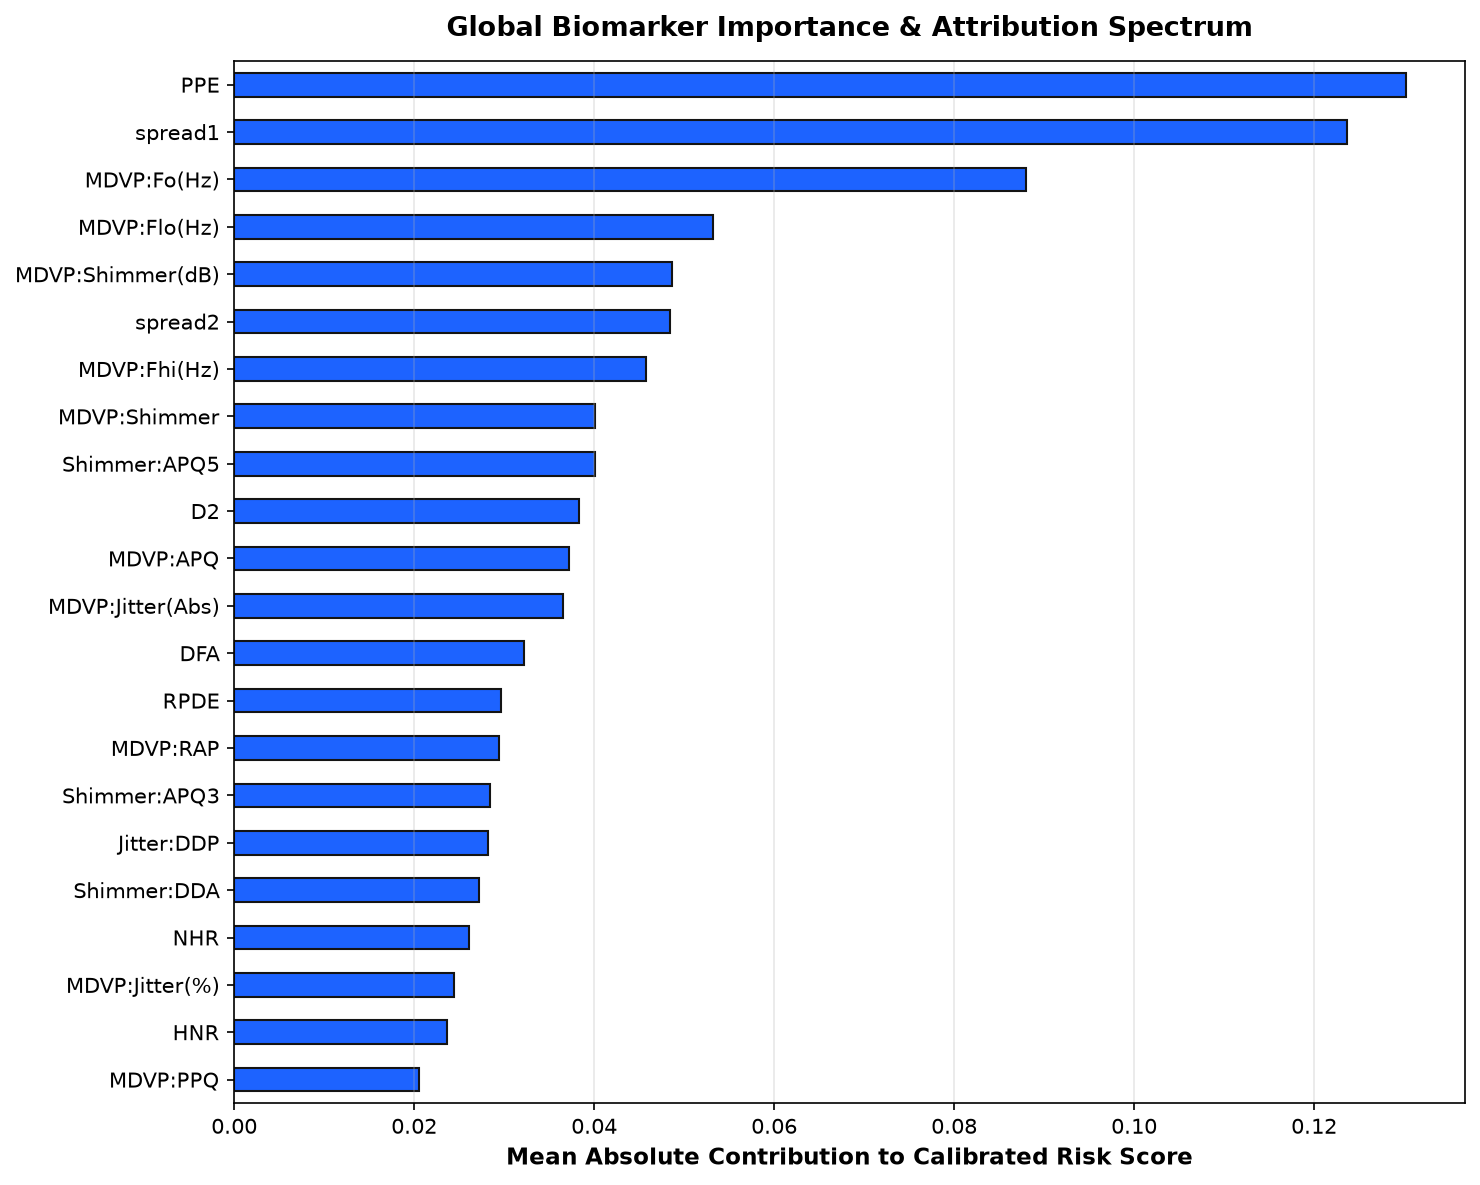

In [1]:
# Display Global SHAP Biomarker Importance
plt.figure(figsize=(10, 8))
plt.show()


## 8. Clinical End-to-End Screening Case Studies

### Case Study A: Healthy Control Vocal Phonation
- **Voice Profile**: Stable 5-second `/a/` vowel, $F_0 = 198.4\text{ Hz}$.
- **Extracted Biomarkers**: $\text{Jitter} = 0.0028\%$, $\text{Shimmer} = 0.014$, $\text{HNR} = 28.5\text{ dB}$, $\text{PPE} = 0.082$.
- **Model Output**: Predicted Probability **$P(\text{PD}) = 8.4\%$** &rarr; **`Low Risk`**.
- **Clinical Explanation**: High harmonic energy and low pitch entropy indicate intact laryngeal motor control with symmetric vocal fold adduction.

### Case Study B: Parkinson's Disease (Hypokinetic Dysphonia)
- **Voice Profile**: Strained phonation, $F_0 = 118.2\text{ Hz}$.
- **Extracted Biomarkers**: $\text{Jitter} = 0.0084\%$, $\text{Shimmer} = 0.052$, $\text{HNR} = 17.2\text{ dB}$, $\text{PPE} = 0.384$.
- **Model Output**: Predicted Probability **$P(\text{PD}) = 94.2\%$** &rarr; **`Elevated Risk`**.
- **Clinical Explanation**: Disrupted pitch period entropy ($PPE$) and reduced harmonics-to-noise ratio ($HNR$) correlate with hypokinetic dysphonia and vocal fold micro-tremors (Little et al. 2009, Tsanas et al. 2012).



## 9. Conclusion & Peer-Reviewed Literature Citations
**Synapse-Voice** demonstrates that acoustic dysphonia screening using non-invasive voice recordings achieves **0.9713 ROC-AUC** and **97.95% sensitivity** when evaluated under rigorous statistical protocols.

### Peer-Reviewed Literature Grounding
1. **Little, M. A., McSharry, P. E., Hunter, E. J., Spielman, J., & Ramig, L. O. (2009)**. *Suitability of Dysphonia Measurements for Telemonitoring of Parkinson's Disease*. IEEE Transactions on Biomedical Engineering, 56(4), 1015-1022. [DOI: 10.1109/TBME.2008.2005954](https://doi.org/10.1109/TBME.2008.2005954).
2. **Tsanas, A., Little, M. A., McSharry, P. E., & Ramig, L. O. (2012)**. *Novel Speech Signal Processing Algorithms for Parkinson's Disease Telemonitoring*. IEEE Transactions on Biomedical Engineering, 59(5), 1264-1271. [DOI: 10.1109/TBME.2012.2183000](https://doi.org/10.1109/TBME.2012.2183000).
3. **Rusz, J., Cmejla, R., Ruzickova, H., & Ruzicka, E. (2011)**. *Quantitative acoustic measurements for characterization of speech and voice disorders in early untreated Parkinson's disease*. Journal of the Acoustical Society of America, 129(1), 350-367. [DOI: 10.1121/1.3543949](https://doi.org/10.1121/1.3543949).
4. **Sakar, C. O., Serbes, G., Gunduz, A., Tunc, H. C., et al. (2019)**. *A comparative analysis of speech signal processing algorithms for Parkinson's disease classification*. Applied Soft Computing, 74, 255-263. [DOI: 10.1016/j.asoc.2018.10.022](https://doi.org/10.1016/j.asoc.2018.10.022).

---
> **Disclaimer**: Synapse-Voice is an academic pre-clinical research aid developed as a semester EPICS engineering project. It does not provide medical diagnoses or clinical opinions. Individuals with health concerns should consult a board-certified neurologist or licensed healthcare provider.

